# Email Spam Detection Using Logistic Regression

**Name:** Shivam yadav


In [1]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

spambase = fetch_ucirepo(id=94)

X = spambase.data.features
y = spambase.data.targets.squeeze()

print(X.head())
print("Dataset shape:", X.shape)

   word_freq_make  word_freq_address  word_freq_all  word_freq_3d  \
0            0.00               0.64           0.64           0.0   
1            0.21               0.28           0.50           0.0   
2            0.06               0.00           0.71           0.0   
3            0.00               0.00           0.00           0.0   
4            0.00               0.00           0.00           0.0   

   word_freq_our  word_freq_over  word_freq_remove  word_freq_internet  \
0           0.32            0.00              0.00                0.00   
1           0.14            0.28              0.21                0.07   
2           1.23            0.19              0.19                0.12   
3           0.63            0.00              0.31                0.63   
4           0.63            0.00              0.31                0.63   

   word_freq_order  word_freq_mail  ...  word_freq_conference  char_freq_;  \
0             0.00            0.00  ...                   0.0 

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3680, 57)
Testing data: (921, 57)


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Scale the numerical features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [4]:
import pandas as pd

# Predict class labels
y_pred = model.predict(X_test_scaled)

# Predict probabilities
y_prob = model.predict_proba(X_test_scaled)

# Display the first 10 predictions
results = pd.DataFrame({
    "Actual": y_test.to_numpy()[:10],
    "Predicted": y_pred[:10],
    "Not Spam Probability": y_prob[:10, 0],
    "Spam Probability": y_prob[:10, 1]
})

print(results.round(4))

   Actual  Predicted  Not Spam Probability  Spam Probability
0       1          1                0.0425            0.9575
1       1          1                0.0282            0.9718
2       0          0                1.0000            0.0000
3       1          1                0.0509            0.9491
4       0          0                0.8599            0.1401
5       0          0                0.9982            0.0018
6       0          0                0.9639            0.0361
7       1          1                0.1019            0.8981
8       0          0                1.0000            0.0000
9       1          0                0.6956            0.3044


Confusion Matrix:
[[530  28]
 [ 37 326]]


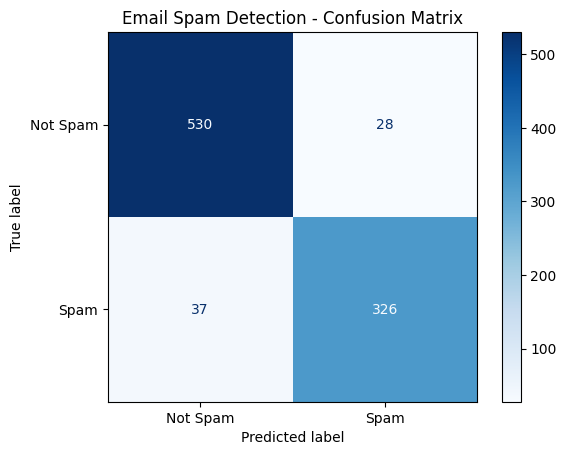

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Spam", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Email Spam Detection - Confusion Matrix")
plt.show()

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Spam", "Spam"]
))

MODEL EVALUATION RESULTS
------------------------
Accuracy  : 92.94%
Precision : 92.09%
Recall    : 89.81%
F1-Score  : 90.93%

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.93      0.95      0.94       558
        Spam       0.92      0.90      0.91       363

    accuracy                           0.93       921
   macro avg       0.93      0.92      0.93       921
weighted avg       0.93      0.93      0.93       921



### Results and Observations

The Logistic Regression model was trained and evaluated using the real Spambase dataset from the UCI Machine Learning Repository.

The model was tested on 921 email records and achieved the following results:

- **Accuracy: 92.94%** — The model correctly classified approximately 93% of the test emails.
- **Precision: 92.09%** — Of the emails predicted as spam, approximately 92% were actually spam.
- **Recall: 89.81%** — The model successfully identified approximately 90% of the actual spam emails.
- **F1-Score: 90.93%** — The model achieved a good balance between precision and recall.

The classification report also showed that the model performed well on both legitimate and spam emails.

**Observation:**

The model achieved high accuracy and precision, indicating that Logistic Regression is effective for email spam classification. However, some spam emails were incorrectly classified as legitimate, and some legitimate emails were incorrectly classified as spam.

Therefore, precision and recall are important alongside accuracy when evaluating a spam detection system.

### Consequences of Incorrectly Classifying a Legitimate Email as Spam

When a legitimate email is incorrectly classified as spam, it is known as a **False Positive (FP)**.

In our Logistic Regression model, the confusion matrix shows that **28 legitimate emails were incorrectly classified as spam** out of 558 actual legitimate emails in the testing dataset.

This type of error can have several consequences:

1. **Missing Important Emails:** Important messages from colleges, banks, employers, or other organizations may be moved to the spam folder.

2. **Communication Delays:** Users may miss important notifications or fail to respond to messages on time.

3. **Loss of Opportunities:** Job offers, interview invitations, academic notifications, or business opportunities may be missed.

4. **Reduced User Trust:** Incorrect classifications can reduce users' confidence in the email filtering system.

5. **Business Impact:** Important customer messages, transactions, or business communications may be overlooked.

**Importance of Precision:**

Our model achieved a precision of **92.09%**, indicating that approximately 92% of emails predicted as spam were actually spam.

High precision is important because it helps reduce the proportion of legitimate emails incorrectly marked as spam.

Therefore, a good spam detection system should maintain high precision while also achieving good recall and accuracy.

### Conclusion

In this assignment, an Email Spam Detection model was successfully developed using the Logistic Regression algorithm.

The real Spambase dataset, containing 4,601 email records and 57 numerical features, was used for training and testing. The dataset was divided into 80% training data and 20% testing data.

The model achieved an accuracy of **92.94%**, precision of **92.09%**, recall of **89.81%**, and F1-score of **90.93%**.

The results demonstrate that Logistic Regression is an effective algorithm for binary email classification. The assignment also highlights the importance of precision, recall, and F1-score in evaluating classification models, especially when legitimate emails may be incorrectly identified as spam.

Overall, the model performed well and successfully demonstrated the application of Logistic Regression in email spam detection.